<a href="https://colab.research.google.com/github/nattaponm/Teach_HID_Doppler_KKN_summerStorm/blob/main/notebooks/02_doppler_dealiasing_outflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2: แก้การพับของความเร็ว Doppler และหาลมกระโชกจากพายุ
### Velocity dealiasing (region-based, phase unwrapping, sounding first guess), divergence and outflow signatures

⏱️ เวลาเรียนโดยประมาณ **75–90 นาที** | ต้องผ่าน: Notebook 1

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **อธิบายและแก้การพับของความเร็ว (dealiasing)** ด้วย 3 วิธี: region-based, unwrap phase และ sounding first guess (หลักการของ 4DD)
2. **ประเมินคุณภาพผลการแก้** ด้วยแผนที่ความต่างระหว่างวิธี และจำนวน "รอยกระโดด" ตามแนวรัศมี
3. **เข้าใจว่าพารามิเตอร์ของอัลกอริทึมมีผลมาก** — ค่าตั้งต้นของซอฟต์แวร์ไม่ได้เหมาะกับทุกพายุ
4. **คำนวณ radial divergence และ azimuthal shear** แล้วระบุลักษณะของ outflow/downburst
5. **เชื่อมสัญญาณ Doppler กับรายงานความเสียหาย** ที่ภูกระดึงและนากลาง และบอกข้อจำกัดจากความสูงของลำคลื่น

## 📖 1. แนวคิดและสมการ

### 1.1 การพับของความเร็ว (velocity aliasing)
เรดาร์วัดความเร็วได้เฉพาะในช่วง $[-V_{ny}, V_{ny}]$ ความเร็วจริงที่เกินช่วงจะถูก "พับ" กลับเข้ามา
$$ V_{true} = V_{obs} + 2\,n\,V_{ny},\qquad n \in \mathbb{Z} $$
งานของ dealiasing คือ **หา $n$ ของทุก gate** — โดยอาศัยหลักว่า **ลมจริงต่อเนื่องในอวกาศ** (ไม่กระโดดทีละ 16.8 m/s ระหว่าง gate ติดกัน)

### 1.2 สามวิธีที่ใช้ใน notebook นี้
| วิธี | หลักการ | จุดแข็ง | จุดอ่อน |
|---|---|---|---|
| **Region-based** (Py-ART) | แบ่ง gate เป็น "ภูมิภาค" ที่ความเร็วต่อเนื่อง แล้วเลื่อนทั้งภูมิภาคทีละ $2V_{ny}$ ให้ขอบต่อกันดีที่สุด | เร็ว, ทนต่อ noise | ภูมิภาคที่ **ไม่ติดกัน** อาจถูกเลื่อนผิดทั้งก้อน |
| **Unwrap phase** (Herráez et al., 2002) | มองความเร็วเป็น "เฟส" $\phi = \pi V/V_{ny}$ แล้วคลายเฟสแบบ 2 มิติ โดยเริ่มจากบริเวณที่เรียบที่สุด | ใช้กันแพร่หลายในภาพ InSAR/MRI | เซลล์ที่แยกขาดจากกันไม่มีข้อมูลอ้างอิง |
| **Sounding first guess** (หลักการขั้นแรกของ 4DD; Eilts & Smith, 1990; James & Houze, 2001) | ใช้ลมจาก sounding คาดความเร็ว $V_{ref}$ แล้วเลือก $n$ ที่ทำให้ใกล้ $V_{ref}$ ที่สุด จากนั้นคลายซ้ำเทียบกับค่าเฉลี่ยเฉพาะที่ | มี "คำตอบอ้างอิง" ภายนอก | ลมในพายุต่างจาก sounding มาก |

ความเร็วที่คาดจากลม sounding $(u, v)$ ที่ความสูงของ gate (มุม azimuth $\varphi$, มุมยก $\theta$)
$$ V_{ref} = (u\sin\varphi + v\cos\varphi)\cos\theta,\qquad n = \mathrm{round}\!\left(\frac{V_{ref} - V_{obs}}{2V_{ny}}\right) $$
> ⚠️ Py-ART รุ่น 2.x **ยกเลิกฟังก์ชัน `dealias_fourdd` แล้ว** จึงเขียนหลักการเองใน `pt.dealias_sounding()` ให้เห็นทุกขั้น

### 1.3 อนุพันธ์ของลม Doppler
$$ \underbrace{\frac{\partial V_r}{\partial r}}_{\text{radial divergence}} \qquad\qquad \underbrace{\frac{1}{r}\frac{\partial V_r}{\partial \varphi}}_{\text{azimuthal shear}} $$
- **Divergence > 0** ใกล้พื้น = ลมแผ่ออก (outflow ของ **downburst**) → คู่สี "เข้าหา–ออกจาก" เรดาร์ **เรียงตามแนวรัศมี**
- **Azimuthal shear** ≠ 0 = ลมหมุน หรือแนวลมเฉือน → คู่สีเรียง **ตามแนวขวาง** กับรัศมี
- เกณฑ์ microburst ของ Fujita (1985): ผลต่างความเร็ว $\Delta V \ge 10$ m s⁻¹ ภายในระยะ < 4 km (ถ้ากว้างกว่านี้ = macroburst)

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–3 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_HID_Doppler_KKN_summerStorm"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "polar_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import polar_tools as pt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_HID_Doppler_KKN_summerStorm/data


In [2]:
snd = pt.load_profile(os.path.join(DATA, "sounding", "sounding_48431_2024-05-03_00Z.csv"))
peak = pt.polar_files(DATA, "09:00", "10:45")
radar = pt.read_volume(pt.polar_files(DATA, "09:30", "09:30")[0])
meta = pt.polar_meta(radar)
reports = kt.load_reports(DATA, meta)
NK = kt.site(reports, "Na Klang")
PK = kt.site(reports, "Phu Kradueng")
ZNK = kt.box_around(meta, 102.2, 17.35, 45)          # กรอบซูม นากลาง–สุวรรณคูหา
VNY = pt.nyquist(radar)
print(f"{mp.tlabel(pt.volume_time(radar))} | Vny = {VNY:.2f} m/s | 2Vny = {2*VNY:.2f} m/s")

09:30 UTC (16:30 LT) | Vny = 8.38 m/s | 2Vny = 16.76 m/s


## 🔧 3. แก้การพับด้วย 3 วิธี (+ ค่าตั้งต้นของ Py-ART)

In [3]:
import time
t0 = time.time(); pt.dealias_region(radar, name="VEL_RB0", tuned=False); t_rb0 = time.time() - t0
t0 = time.time(); pt.dealias_region(radar);                          t_rb = time.time() - t0
t0 = time.time(); pt.dealias_unwrap(radar);                          t_up = time.time() - t0
t0 = time.time(); pt.dealias_sounding(radar, snd);                   t_sn = time.time() - t0
rep = pt.dealias_report(radar, ("VEL_RB0", "VEL_RB", "VEL_UP", "VEL_SND"))
rep["jumps>Vny"] = [pt.jump_count(radar, f) for f in rep.index]
rep["time_s"] = np.round([t_rb0, t_rb, t_up, t_sn], 2)
print("รอยกระโดด > Vny ในข้อมูลก่อนแก้ (aliased):", pt.jump_count(radar, "velocity_qc"))
rep

รอยกระโดด > Vny ในข้อมูลก่อนแก้ (aliased): 647


,valid_gates,unfolded_gates,unfolded_pct,v_min,v_max,v_p01,v_p99,jumps>Vny,time_s
method,,,,,,,,,
VEL_RB0,36256,5090,14.04,-26.42,21.26,-16.66,10.86,10,0.08
VEL_RB,36256,1415,3.90,-14.86,20.46,-9.16,9.16,0,0.06
VEL_UP,36256,1458,4.02,-14.86,20.46,-9.16,9.16,0,0.10
VEL_SND,34072,2474,7.26,-15.96,14.06,-11.36,9.16,59,0.17


- `VEL_RB0` = region-based ด้วย **ค่าตั้งต้นของ Py-ART** (`skip_between_rays=100`, `skip_along_ray=100`, `centered=True`)
- `VEL_RB` = region-based ที่ **ปรับให้เหมาะกับเซลล์ที่กระจัดกระจาย** (`skip_*=0`, `centered=False`)
- คอลัมน์ `jumps>Vny` นับคู่ gate ติดกันที่ความเร็วต่างกันเกิน $V_{ny}$ — ข้อมูลดิบมีหลายร้อยคู่ หลังแก้เหลือน้อยมาก
- แต่ **jump count ตรวจไม่พบ "การเลื่อนผิดทั้งก้อน"** (ทั้งเซลล์เลื่อนไป $2V_{ny}$ พร้อมกัน ขอบภายในยังเรียบ) → ต้องดูแผนที่และเทียบหลายวิธี

## 🗺️ 4. เปรียบเทียบบนแผนที่: นากลาง–สุวรรณคูหา 09:30 UTC

บันทึกรูปแล้ว: figures/nb2_dealias_methods.png, figures/nb2_dealias_methods.pdf


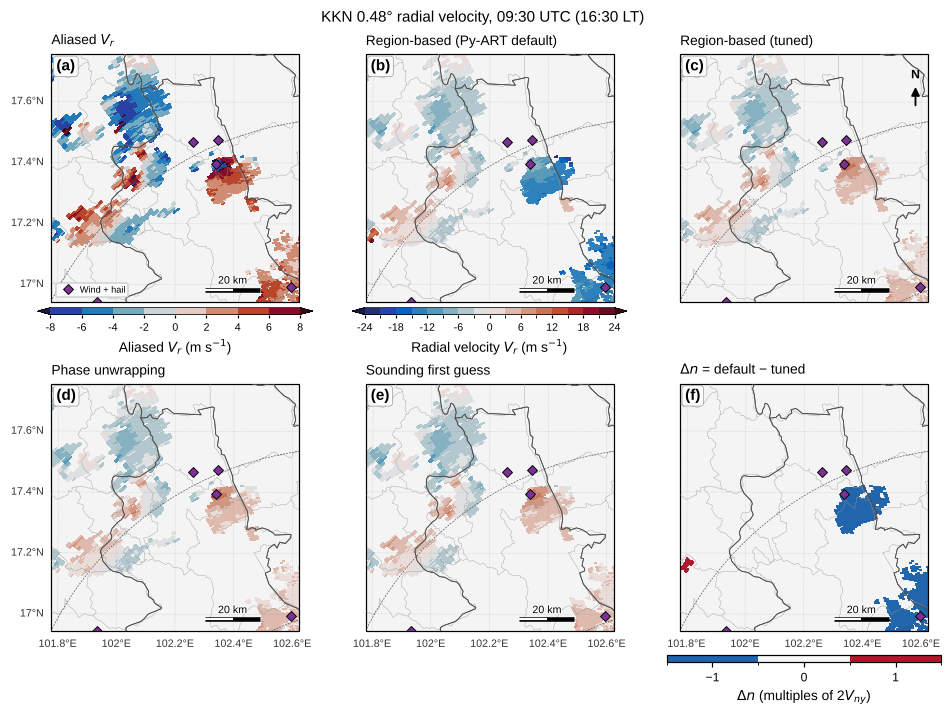

In [4]:
panels = [("velocity_qc", "VA", "Aliased $V_r$"), ("VEL_RB0", "V", "Region-based (Py-ART default)"),
          ("VEL_RB", "V", "Region-based (tuned)"), ("VEL_UP", "V", "Phase unwrapping"),
          ("VEL_SND", "V", "Sounding first guess")]
fig, axs = mp.map_panels(2, 3, meta, panel_width=2.9, zoom=ZNK)
for k, (ax, (f, kind, ttl)) in enumerate(zip(axs, panels)):
    im = pt.ppi_map(ax, radar, f, 0, meta, kind=kind, zoom=ZNK, title=ttl, north=(k == 2),
                    gridline_labels=(("left",) if k % 3 == 0 else ()) + (("bottom",) if k >= 3 else ()))
    mp.add_reports(ax, reports, legend=(k == 0))
    if k in (0, 1):
        mp.add_colorbar(fig, im, ax, shrink=0.9, extend="both")
# panel f: ความต่าง default − tuned (หน่วยเป็นจำนวนเท่าของ 2Vny)
diff = (pt.field_data(radar, "VEL_RB0") - pt.field_data(radar, "VEL_RB")) / (2 * VNY)
diff[np.abs(diff) < 0.5] = np.nan                      # แสดงเฉพาะ gate ที่ต่างกัน
pt.add_field(radar, "N_DIFF", diff, "", "Folding-number difference")
import matplotlib as mpl
cm_d = mpl.colors.ListedColormap(["#2166ac", "#f7f7f7", "#b2182b"])
im = pt.ppi_map(axs[5], radar, "N_DIFF", 0, meta, zoom=ZNK, cmap=cm_d,
                norm=mpl.colors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3),
                title="$\\Delta n$ = default − tuned", north=False, gridline_labels=("bottom",))
mp.add_reports(axs[5], reports, legend=False)
cb = fig.colorbar(im, ax=axs[5], orientation="horizontal", shrink=0.9, pad=0.02, aspect=40, ticks=[-1, 0, 1])
cb.set_label("$\\Delta n$ (multiples of 2$V_{ny}$)")
mp.panel_labels(axs)
fig.suptitle(f"KKN 0.48° radial velocity, {mp.tlabel(pt.volume_time(radar))}", fontsize=10)
mp.save_figure(fig, "nb2_dealias_methods")
plt.show()

**อ่านแผนที่:** เรดาร์อยู่ทาง **ตะวันออกเฉียงใต้** ของกรอบนี้ สีน้ำเงิน = ลมพัดเข้าหาเรดาร์ (ไปทาง SE) สีแดง = พัดออก (ไปทาง NW)
- (b) ค่าตั้งต้นของ Py-ART **เลื่อนเซลล์ที่นากลางทั้งก้อน** ไปเป็นค่าลบมาก ขณะที่ (c)–(e) ให้ผลใกล้กัน — (f) แสดงตำแหน่งที่เลื่อนต่างกัน 1 รอบ ($\Delta n = \pm1$)
- เหตุผล: ค่าตั้งต้นยอมให้เชื่อมภูมิภาคข้ามช่องว่างได้ไกล 100 gate/ray และจัดให้ความเร็วเฉลี่ยของทั้ง sweep ใกล้ 0 — ใช้ได้ดีกับฝนแผ่กว้าง แต่ **ไม่เหมาะกับเซลล์พายุฤดูร้อนที่กระจายเป็นหย่อม**
- **บทเรียน:** อย่าเชื่อผลจากค่าตั้งต้นของซอฟต์แวร์โดยไม่ตรวจ — เทียบหลายวิธี และดูความสมเหตุสมผลทางอุตุนิยมวิทยา

## ⏱️ 5. ความสอดคล้องของวิธีต่าง ๆ ตลอดช่วงพีค (8 volume)

บันทึกรูปแล้ว: figures/nb2_dealias_agreement.png, figures/nb2_dealias_agreement.pdf


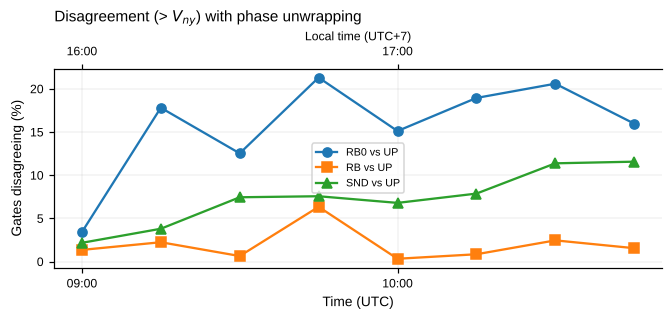

,RB0 vs UP,RB vs UP,SND vs UP
time,,,
2024-05-03 09:00:00,3.4,1.3,2.2
2024-05-03 09:15:00,17.8,2.2,3.8
2024-05-03 09:30:00,12.5,0.6,7.4
2024-05-03 09:45:00,21.3,6.3,7.6
2024-05-03 10:00:00,15.1,0.3,6.8
2024-05-03 10:15:00,18.9,0.8,7.9
2024-05-03 10:30:00,20.6,2.5,11.4
2024-05-03 10:45:00,16.0,1.5,11.6


In [5]:
rows = []
for f in peak:
    r = pt.read_volume(f)
    pt.dealias_region(r, name="VEL_RB0", tuned=False); pt.dealias_region(r)
    pt.dealias_unwrap(r); pt.dealias_sounding(r, snd)
    V = {k: pt.field_data(r, k) for k in ("VEL_RB0", "VEL_RB", "VEL_UP", "VEL_SND")}
    row = {"time": pt.volume_time(r)}
    for a, b in (("VEL_RB0", "VEL_UP"), ("VEL_RB", "VEL_UP"), ("VEL_SND", "VEL_UP")):
        ok = np.isfinite(V[a]) & np.isfinite(V[b])
        row[f"{a[4:]} vs UP"] = 100 * np.mean(np.abs(V[a] - V[b])[ok] > pt.nyquist(r))
    rows.append(row)
agree = pd.DataFrame(rows).set_index("time")
fig, ax = plt.subplots(figsize=(6, 2.8), layout="constrained")
for c, mk in zip(agree.columns, ("o", "s", "^")):
    ax.plot(agree.index, agree[c], marker=mk, label=c)
ax.set_ylabel("Gates disagreeing (%)"); ax.legend(fontsize=7); ax.grid(lw=0.3, alpha=0.5)
mp.time_axis(ax, interval_h=1)
ax.set_title("Disagreement (> $V_{ny}$) with phase unwrapping", loc="left")
mp.save_figure(fig, "nb2_dealias_agreement")
plt.show()
agree.round(1)

- region-based แบบปรับแล้ว **ต่างจาก unwrap phase เพียง ~0–6%** ของ gate, sounding first guess ต่าง ~2–12% (มากขึ้นเมื่อพายุแตกเป็นหย่อมช่วง 10:30–10:45) ขณะที่ค่าตั้งต้นต่างได้ 12–21%
- เมื่อสามวิธีที่หลักการต่างกันให้คำตอบเดียวกัน → **ความเชื่อมั่นสูงขึ้น** (แนวคิด *ensemble/consensus dealiasing*)
- จากนี้ไปใช้ **`VEL_RB` (tuned)** เป็นความเร็วหลักของ repo นี้

## 🌬️ 6. ลมจาก sounding เป็น first guess ได้ดีแค่ไหน?

บันทึกรูปแล้ว: figures/nb2_sounding_reference.png, figures/nb2_sounding_reference.pdf


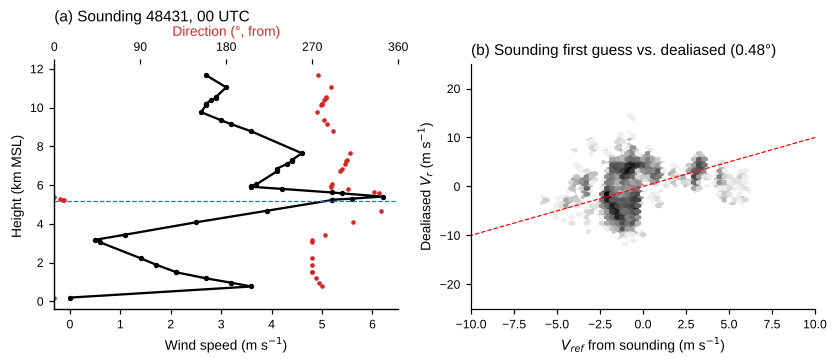

ลมเฉลี่ย 0–6 km จาก sounding = 3.2 m/s | |V_r| p95 ในพายุ = 7.4 m/s


In [6]:
h, spd, wdir = pt.sounding_wind_profile(snd)
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.2), layout="constrained")
m = h < 12000
axs[0].plot(spd[m], h[m] / 1000, "k-o", ms=2.5)
axs[0].set_xlabel("Wind speed (m s$^{-1}$)"); axs[0].set_ylabel("Height (km MSL)")
ax2 = axs[0].twiny(); ax2.plot(wdir[m], h[m] / 1000, ".", color="tab:red", ms=4)
ax2.set_xlim(0, 360); ax2.set_xticks([0, 90, 180, 270, 360]); ax2.set_xlabel("Direction (°, from)", color="tab:red")
axs[0].axhline(pt.isotherm_height(snd, 0) / 1000, color="tab:blue", ls="--", lw=0.8)
axs[0].set_title("(a) Sounding 48431, 00 UTC", loc="left", pad=28)
vsim = pt.field_data(radar, "VEL_SIM", 0)
vrb = pt.field_data(radar, "VEL_RB", 0)
ok = np.isfinite(vrb)
axs[1].hexbin(vsim[ok], vrb[ok], gridsize=40, mincnt=1, cmap="Greys", bins="log")
axs[1].plot([-25, 25], [-25, 25], "r--", lw=0.8)
axs[1].set_xlim(-10, 10); axs[1].set_ylim(-25, 25)
axs[1].set_xlabel("$V_{ref}$ from sounding (m s$^{-1}$)"); axs[1].set_ylabel("Dealiased $V_r$ (m s$^{-1}$)")
axs[1].set_title("(b) Sounding first guess vs. dealiased (0.48°)", loc="left")
mp.save_figure(fig, "nb2_sounding_reference")
plt.show()
print(f"ลมเฉลี่ย 0–6 km จาก sounding = {np.mean(spd[(h > 0) & (h < 6000)]):.1f} m/s | |V_r| p95 ในพายุ = {np.nanpercentile(np.abs(vrb), 95):.1f} m/s")

- เช้าวันที่ 3 พ.ค. **ลมระดับต่ำ–กลางอ่อนมาก** (< 6 m/s) → $V_{ref}$ อยู่ในช่วง ±6 m/s ขณะที่ลมในพายุแรงกว่ามาก
- sounding first guess จึงทำงานได้ดีกับ **ลมพื้นหลัง** แต่ต้องอาศัย pass ที่ 2 (ค่าเฉลี่ยเฉพาะที่) แก้บริเวณ outflow
- ในพายุฤดูร้อนของอีสาน **ลมพายุ (storm-scale) แรงกว่าลมสิ่งแวดล้อม** → นี่เป็นเหตุผลที่ downburst อันตราย: เป็นลมที่พายุสร้างขึ้นเอง ไม่ใช่ลมจากระบบใหญ่

## 💨 7. Divergence และ azimuthal shear: หาลายเซ็นของ downburst

บันทึกรูปแล้ว: figures/nb2_divergence_shear.png, figures/nb2_divergence_shear.pdf


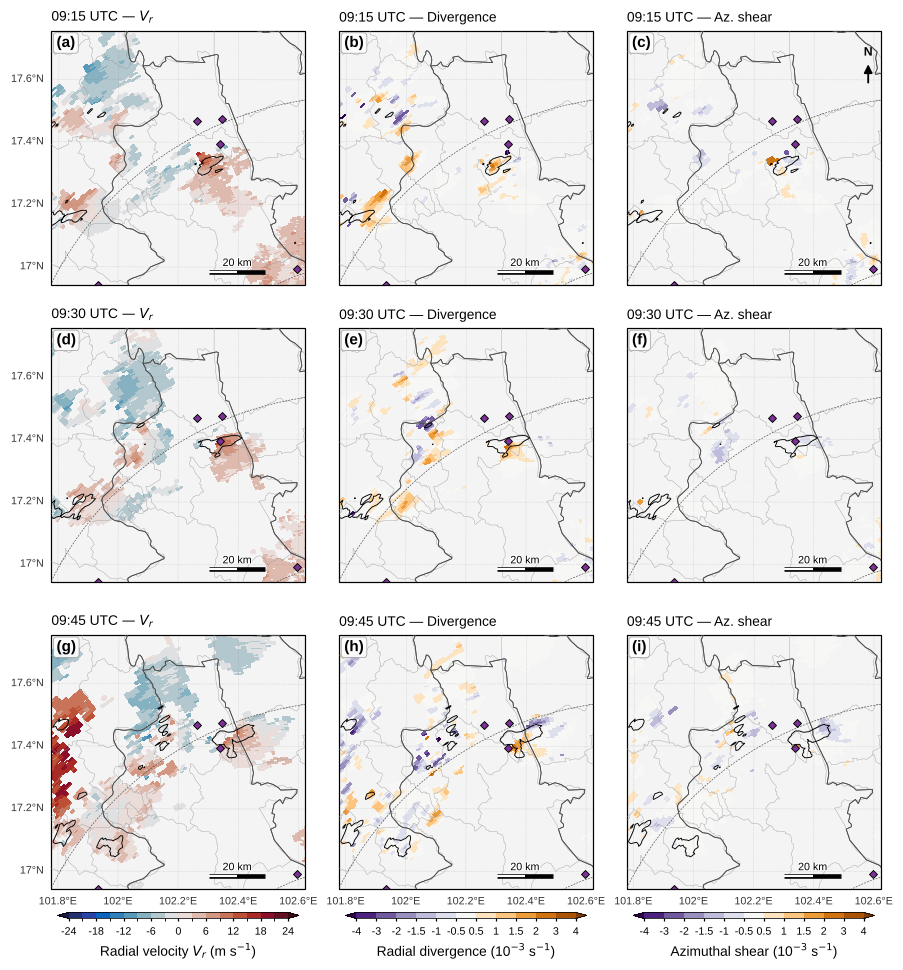

In [7]:
times = ["09:15", "09:30", "09:45"]
vols = {}
for t in times:
    r = pt.read_volume(pt.polar_files(DATA, t, t)[0])
    pt.dealias_region(r); pt.radial_divergence(r); pt.azimuthal_shear(r)
    vols[t] = r
fig, axs = mp.map_panels(3, 3, meta, panel_width=2.7, zoom=ZNK)
for i, t in enumerate(times):
    r = vols[t]
    for j, (f, kind) in enumerate((("VEL_RB", "V"), ("DIV", "DIV"), ("AZSHEAR", "AZSHEAR"))):
        ax = axs[i * 3 + j]
        im = pt.ppi_map(ax, r, f, 0, meta, kind=kind, zoom=ZNK, north=(i == 0 and j == 2),
                        title=f"{t} UTC — " + ("$V_r$" if j == 0 else "Divergence" if j == 1 else "Az. shear"),
                        gridline_labels=(("left",) if j == 0 else ()) + (("bottom",) if i == 2 else ()))
        x, y, _ = r.get_gate_x_y_z(0)
        ax.contour(x, y, np.nan_to_num(pt.field_data(r, "reflectivity_qc", 0), nan=0), levels=[40],
                   colors="k", linewidths=0.6, transform=mp.get_crs(meta), zorder=6)
        mp.add_reports(ax, reports, legend=False, ms=4)
        if i == 2:
            mp.add_colorbar(fig, im, ax, shrink=0.95, extend="both")
mp.panel_labels(axs)
mp.save_figure(fig, "nb2_divergence_shear")
plt.show()

**อ่านแผนที่ (เส้นดำ = 40 dBZ):**
- ที่ขอบของแกนพายุใกล้ อ.นากลาง มี **คู่สีเข้าหา–ออกจาก** และ divergence เป็นบวก (สีส้ม) อยู่ติดกับแกน ≥ 40 dBZ ในช่วง 09:15–09:45 UTC (16:15–16:45 น.)
- ช่วงเวลานี้ตรงกับรายงานลมกระโชกแรง+ลูกเห็บ ~16:30 น.
- ⚠️ ลำคลื่นอยู่สูง ~1.9 km เหนือนากลาง → เห็น **ส่วนบนของ outflow หรือ downdraft ที่กำลังลง** ไม่ใช่ลมที่พื้นโดยตรง และค่า divergence ขึ้นกับขนาดหน้าต่างที่ใช้ทำให้เรียบ

## 📈 8. อนุกรมเวลารอบจุดรายงาน: ภูกระดึง (14:00 น.) และนากลาง (~16:30 น.)

บันทึกรูปแล้ว: figures/nb2_site_timeseries.png, figures/nb2_site_timeseries.pdf


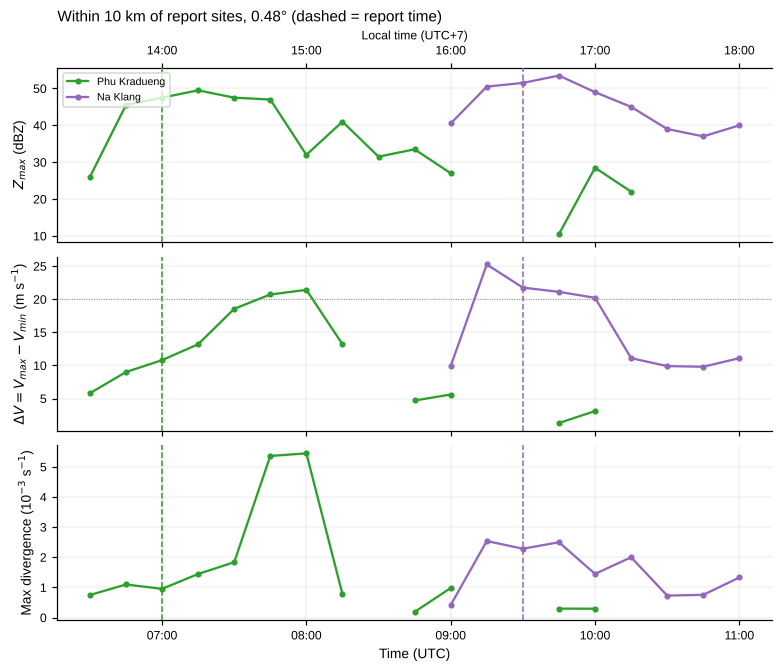

time,2024-05-03 06:00:00,2024-05-03 06:15:00,2024-05-03 06:30:00,2024-05-03 06:45:00,2024-05-03 07:00:00,2024-05-03 07:15:00,2024-05-03 07:30:00,2024-05-03 07:45:00,2024-05-03 08:00:00,2024-05-03 08:15:00,...,2024-05-03 08:45:00,2024-05-03 09:00:00,2024-05-03 09:15:00,2024-05-03 09:30:00,2024-05-03 09:45:00,2024-05-03 10:00:00,2024-05-03 10:15:00,2024-05-03 10:30:00,2024-05-03 10:45:00,2024-05-03 11:00:00
site,,,,,,,,,,,,,,,,,,,,,
Na Klang,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,9.9,25.3,21.8,21.1,20.2,11.1,9.9,9.8,11.1
Phu Kradueng,NaN,NaN,5.8,9.0,10.8,13.2,18.6,20.7,21.4,13.2,...,4.7,5.6,NaN,NaN,1.3,3.1,NaN,NaN,NaN,NaN


In [8]:
rows = []
for f in pt.polar_files(DATA, "06:00", "11:00"):
    r = pt.read_volume(f)
    pt.dealias_region(r); pt.radial_divergence(r)
    for name, s in (("Phu Kradueng", PK), ("Na Klang", NK)):
        st_ = pt.site_velocity_stats(r, meta, s["lon"], s["lat"], radius_km=10)
        st_.update(site=name, time=pt.volume_time(r))
        rows.append(st_)
ts = pd.DataFrame(rows)
date0 = pt.volume_time(radar).replace(hour=0, minute=0)
fig, axs = plt.subplots(3, 1, figsize=(7, 6), sharex=True, layout="constrained")
for name, col in (("Phu Kradueng", "tab:green"), ("Na Klang", "tab:purple")):
    d = ts[ts["site"] == name]
    axs[0].plot(d["time"], d["Zmax"], "-o", ms=3, color=col, label=name)
    axs[1].plot(d["time"], d["dV"], "-o", ms=3, color=col)
    axs[2].plot(d["time"], d["DIVmax"], "-o", ms=3, color=col)
    tr = kt.report_time_utc(kt.site(reports, name), date0)
    for ax in axs:
        ax.axvline(tr, color=col, ls="--", lw=1)
axs[0].set_ylabel("$Z_{max}$ (dBZ)"); axs[0].legend(fontsize=7, loc="upper left")
axs[1].set_ylabel("$\\Delta V = V_{max}-V_{min}$ (m s$^{-1}$)"); axs[1].axhline(20, color="0.5", lw=0.6, ls=":")
axs[2].set_ylabel("Max divergence (10$^{-3}$ s$^{-1}$)")
for ax in axs:
    ax.grid(lw=0.3, alpha=0.5)
mp.time_axis(axs[0], interval_h=1)
mp.time_axis(axs[2], interval_h=1, local_top=False)
axs[0].set_xlabel(""); axs[0].tick_params(labelbottom=False)
axs[0].set_title("Within 10 km of report sites, 0.48° (dashed = report time)", loc="left")
mp.save_figure(fig, "nb2_site_timeseries")
plt.show()
ts.pivot(index="time", columns="site", values="dV").round(1).T

- **นากลาง:** $\Delta V$ กระโดดจาก ~10 เป็น **> 20 m/s ตั้งแต่ 09:15 UTC (16:15 น.)** และคงอยู่ถึง 10:00 UTC — ครอบคลุมเวลารายงาน ~16:30 น.
- **ภูกระดึง:** $\Delta V$ เพิ่มขึ้นต่อเนื่องหลัง 07:00 UTC (14:00 น.) และสูงสุดราว 07:45–08:00 UTC — สัญญาณมาช้ากว่ารายงานเล็กน้อย
  (เวลาในข่าวเป็นเวลาโดยประมาณ, ลำคลื่นอยู่สูง ~1.8 km และ $\Delta V$ รวมทั้งการเคลื่อนที่ของพายุและลมหมุน)
- $\Delta V$ เป็นตัวชี้วัดอย่างง่ายที่ใช้ได้ทันที แต่ไม่ได้แยก divergence ออกจาก rotation → ต้องดูแผนที่ประกอบเสมอ

---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 2.1: พารามิเตอร์ `skip_between_rays` มีผลแค่ไหน?
ใช้ volume 09:45 UTC รัน `pt.dealias_region(r, tuned=False, skip_between_rays=S, skip_along_ray=S, centered=False)`
กับ `S = 0, 5, 20, 50, 100` แล้วคำนวณ (1) % gate ที่ต่างจาก unwrap phase เกิน $V_{ny}$ และ (2) jump count

**คำถาม:** ค่า S เท่าไรเริ่มทำให้ผลผิด? ทำไม jump count จึงไม่เพิ่มตาม?

<details>
<summary><b>💡 คำใบ้</b></summary>

- อ่าน: `r = pt.read_volume(pt.polar_files(DATA, "09:45", "09:45")[0])` และ `pt.dealias_unwrap(r)` ก่อน
- ใส่ชื่อ field ใหม่ทุกครั้ง: `name=f"RB_{S}"`
- % ต่าง: `np.mean(np.abs(a - b)[ok] > pt.nyquist(r)) * 100`

</details>

In [9]:
# ✍️ แบบฝึกหัด 2.1 — เขียนโค้ดของคุณที่นี่

In [10]:
#@title ✅ เฉลยแบบฝึกหัด 2.1
r = pt.read_volume(pt.polar_files(DATA, "09:45", "09:45")[0])
pt.dealias_unwrap(r)
up = pt.field_data(r, "VEL_UP")
out = []
for S in (0, 5, 20, 50, 100):
    pt.dealias_region(r, name=f"RB_{S}", tuned=False, skip_between_rays=S, skip_along_ray=S, centered=False)
    a = pt.field_data(r, f"RB_{S}")
    ok = np.isfinite(a) & np.isfinite(up)
    out.append({"skip": S, "disagree_vs_UP_%": 100 * np.mean(np.abs(a - up)[ok] > pt.nyquist(r)),
                "jumps": pt.jump_count(r, f"RB_{S}")})
out = pd.DataFrame(out).set_index("skip").round(2)
print(out)
n_valid = int(np.isfinite(up).sum())
d0, dmax = out["disagree_vs_UP_%"].iloc[0], out["disagree_vs_UP_%"].max()
print(f"\n→ ความต่างจาก unwrap เพิ่มจาก {d0:.1f}% (skip=0) เป็น {dmax:.1f}% (≈ {dmax/100*n_valid:,.0f} gate จาก {n_valid:,})"
      "\n  เพราะอัลกอริทึมเชื่อมเซลล์ที่อยู่ห่างกันแล้วเลื่อนให้ 'ต่อกัน' ทั้งที่ไม่ได้ต่อกันจริง")
print(f"  แต่ jump count เพิ่มเพียง {out['jumps'].iloc[0]} → {out['jumps'].max()} คู่ (ข้อมูลดิบมี {pt.jump_count(r, 'velocity_qc')} คู่)"
      "\n  เพราะความผิดเป็นการเลื่อนทั้งเซลล์ ขอบภายในยังเรียบ → jump count อย่างเดียวไม่พอ ต้องเทียบหลายวิธีหรือมีข้อมูลอ้างอิงภายนอก")

      disagree_vs_UP_%  jumps
skip                         
0                 6.33      2
5                11.38      6
20               15.08     17
50               33.62     26
100              21.30     26

→ ความต่างจาก unwrap เพิ่มจาก 6.3% (skip=0) เป็น 33.6% (≈ 11,369 gate จาก 33,815)
  เพราะอัลกอริทึมเชื่อมเซลล์ที่อยู่ห่างกันแล้วเลื่อนให้ 'ต่อกัน' ทั้งที่ไม่ได้ต่อกันจริง
  แต่ jump count เพิ่มเพียง 2 → 26 คู่ (ข้อมูลดิบมี 598 คู่)
  เพราะความผิดเป็นการเลื่อนทั้งเซลล์ ขอบภายในยังเรียบ → jump count อย่างเดียวไม่พอ ต้องเทียบหลายวิธีหรือมีข้อมูลอ้างอิงภายนอก


### 🧪 แบบฝึกหัด 2.2: ลายเซ็น downburst ที่นากลางแรงที่สุดเมื่อไร และแรงแค่ไหน?
สำหรับ 8 volume ใน `peak` จงหา (1) $\Delta V$ ในรัศมี **5 km** และ **10 km** รอบจุด Na Klang (2) divergence สูงสุด และ (3) ระยะ/ทิศทางของ gate ที่มี divergence สูงสุดจากจุดรายงาน

**คำถาม:** ผลเข้าเกณฑ์ microburst ($\Delta V \ge 10$ m/s ภายใน 4 km) หรือ macroburst? เวลาที่แรงที่สุดตรงกับรายงาน 16:30 น. หรือไม่?

<details>
<summary><b>💡 คำใบ้</b></summary>

- `pt.site_velocity_stats(r, meta, NK["lon"], NK["lat"], radius_km=5)` คืน dict ที่มี `dV`, `DIVmax`
- ตำแหน่ง gate: `r.gate_x["data"]`, `r.gate_y["data"]` ใช้ร่วมกับ `pt.site_gates(...)` และ `np.nanargmax`
- ตำแหน่งจุดรายงานในพิกัดเดียวกัน: `NK["x"], NK["y"]`

</details>

In [11]:
# ✍️ แบบฝึกหัด 2.2 — เขียนโค้ดของคุณที่นี่

In [12]:
#@title ✅ เฉลยแบบฝึกหัด 2.2
rows = []
for f in peak:
    r = pt.read_volume(f)
    pt.dealias_region(r); pt.radial_divergence(r)
    s5 = pt.site_velocity_stats(r, meta, NK["lon"], NK["lat"], 5)
    s10 = pt.site_velocity_stats(r, meta, NK["lon"], NK["lat"], 10)
    m = pt.site_gates(r, meta, NK["lon"], NK["lat"], 10, sweeps=[0])
    d = np.where(m, pt.field_data(r, "DIV"), np.nan)
    row = {"time_UTC": pt.volume_time(r).strftime("%H:%M"), "dV_5km": s5["dV"], "dV_10km": s10["dV"],
           "DIVmax_1e-3": s10["DIVmax"]}
    if np.isfinite(d).any():
        k = np.unravel_index(np.nanargmax(d), d.shape)
        dx, dy = r.gate_x["data"][k] - NK["x"], r.gate_y["data"][k] - NK["y"]
        row.update(dist_km=np.hypot(dx, dy) / 1000, bearing_deg=np.degrees(np.arctan2(dx, dy)) % 360)
    rows.append(row)
db = pd.DataFrame(rows).set_index("time_UTC").round(1)
print(db)
best = db["dV_5km"].idxmax()
print(f"\n→ ΔV ในรัศมี 5 km สูงสุด {db['dV_5km'].max():.1f} m/s เวลา {best} UTC "
      f"({(pd.to_datetime(best) + pd.Timedelta(hours=7)).strftime('%H:%M')} น.) — รายงาน ~16:30 น.")
print("  ΔV ≥ 10 m/s ภายในวงที่เล็กกว่า 10 km เข้าเค้า microburst/macroburst ตาม Fujita แต่ต้องตรวจว่าเป็นคู่ตามแนวรัศมี (divergence) จริง ไม่ใช่การหมุน"
      "\n  และลำคลื่นสูง ~1.9 km จึงประเมินลมที่พื้นได้ต่ำกว่าจริงหรือคลาดตำแหน่ง")

          dV_5km  dV_10km  DIVmax_1e-3  dist_km  bearing_deg
time_UTC                                                    
09:00        NaN      9.9          0.4      5.2        193.7
09:15       15.4     25.3          2.5      9.2        217.5
09:30       19.7     21.8          2.3      1.9        194.5
09:45       19.4     21.1          2.5      2.6         88.7
10:00       16.4     20.2          1.4      7.1         42.0
10:15        9.5     11.1          2.0      6.9         13.2
10:30        3.6      9.9          0.7      9.1         26.0
10:45        8.1      9.8          0.8      9.1         37.5

→ ΔV ในรัศมี 5 km สูงสุด 19.7 m/s เวลา 09:30 UTC (16:30 น.) — รายงาน ~16:30 น.
  ΔV ≥ 10 m/s ภายในวงที่เล็กกว่า 10 km เข้าเค้า microburst/macroburst ตาม Fujita แต่ต้องตรวจว่าเป็นคู่ตามแนวรัศมี (divergence) จริง ไม่ใช่การหมุน
  และลำคลื่นสูง ~1.9 km จึงประเมินลมที่พื้นได้ต่ำกว่าจริงหรือคลาดตำแหน่ง


### 🧪 แบบฝึกหัด 2.3: ถ้าไม่มี sounding จะเป็นอย่างไร?
รัน `pt.dealias_sounding()` อีกครั้ง โดยใช้ sounding ปลอมที่ **ลมเป็นศูนย์ทุกระดับ** (copy `snd` แล้วตั้ง `speed = 0`)
เปรียบเทียบกับผลที่ใช้ sounding จริง: กี่ % ของ gate ที่ได้ค่า $n$ ต่างกัน? และ gate ที่ต่างอยู่ที่ไหน (เทียบกับ unwrap phase ว่าแบบไหนถูกกว่า)

**คำถาม:** ลมพื้นหลังที่อ่อนมาก (~3 m/s) ยังมีผลหรือไม่? sounding ที่อยู่ห่างและเก่ากว่า 9 ชั่วโมงเป็นตัวแทนได้ดีแค่ไหน? ในสถานการณ์ใด sounding จะสำคัญมาก (คำใบ้: ลมมรสุมตะวันตกเฉียงใต้, พายุหมุนเขตร้อน)

<details>
<summary><b>💡 คำใบ้</b></summary>

- `snd0 = snd.copy(); snd0["speed"] = 0.0`
- ใช้ชื่อ field ต่างกัน: `pt.dealias_sounding(r, snd0, name="VEL_SND0")`

</details>

In [13]:
# ✍️ แบบฝึกหัด 2.3 — เขียนโค้ดของคุณที่นี่

In [14]:
#@title ✅ เฉลยแบบฝึกหัด 2.3
snd0 = snd.copy(); snd0["speed"] = 0.0
res = []
for f in peak:
    r = pt.read_volume(f)
    pt.dealias_unwrap(r)
    pt.dealias_sounding(r, snd, name="VEL_SND")
    pt.dealias_sounding(r, snd0, name="VEL_SND0")
    a, b, u = pt.field_data(r, "VEL_SND"), pt.field_data(r, "VEL_SND0"), pt.field_data(r, "VEL_UP")
    vny = pt.nyquist(r)
    ok = np.isfinite(a) & np.isfinite(b) & np.isfinite(u)
    dif = ok & (np.abs(a - b) > vny)
    res.append({"time": pt.volume_time(r).strftime("%H:%M"), "different_n_%": 100 * dif.sum() / ok.sum(),
                "real_snd_agrees_UP_%": 100 * np.mean(np.abs(a - u)[dif] < vny) if dif.any() else np.nan,
                "zero_wind_agrees_UP_%": 100 * np.mean(np.abs(b - u)[dif] < vny) if dif.any() else np.nan})
res = pd.DataFrame(res).set_index("time").round(1)
print(res)
print(f"\n→ ต่างกันเฉลี่ย {res['different_n_%'].mean():.1f}% ของ gate แม้ลมพื้นหลังจะอ่อน — ส่วนใหญ่เป็นเซลล์เล็กที่แยกขาด"
      "\n  ซึ่งค่าเฉลี่ยเฉพาะที่ (pass 2) มีข้อมูลไม่พอ ค่า n จึงถูกกำหนดโดย first guess โดยตรง")
ra, za = res['real_snd_agrees_UP_%'].mean(), res['zero_wind_agrees_UP_%'].mean()
print(f"  ใน gate ที่ต่างกัน: ใช้ sounding จริงตรงกับ unwrap {ra:.0f}% | ใช้ลมศูนย์ตรงกับ unwrap {za:.0f}%")
if za > ra:
    print("  → น่าสนใจ: ลมศูนย์กลับให้ผลใกล้ unwrap มากกว่า! sounding 00Z ที่นครราชสีมา (ห่างจากนากลาง ~270 km และก่อนพายุ ~9 ชม.)"
          "\n    อาจไม่ใช่ตัวแทนลมรอบพายุตอนบ่าย — first guess ที่ไม่ตรงอาจแย่กว่าการไม่มีเลย (แต่ unwrap ก็ไม่ใช่ความจริง 100%)")
print("  sounding จะสำคัญยิ่งขึ้นเมื่อลมพื้นหลังแรงใกล้หรือเกิน Vny เช่น ลมมรสุม 15–20 m/s ที่ 850 hPa หรือพายุหมุนเขตร้อน"
      "\n  ซึ่งพื้นที่กว้างพับพร้อมกัน และวิธีที่อาศัยความต่อเนื่องเพียงอย่างเดียวไม่มีจุดอ้างอิง")

       different_n_%  real_snd_agrees_UP_%  zero_wind_agrees_UP_%
time                                                             
09:00            2.2                  45.8                   54.2
09:15            4.5                  33.5                   66.5
09:30            6.8                  11.5                   88.5
09:45            4.9                  59.7                   40.3
10:00            7.9                  27.4                   72.6
10:15            9.2                  40.2                   59.8
10:30           10.0                  18.5                   81.5
10:45            9.0                   3.3                   96.7

→ ต่างกันเฉลี่ย 6.8% ของ gate แม้ลมพื้นหลังจะอ่อน — ส่วนใหญ่เป็นเซลล์เล็กที่แยกขาด
  ซึ่งค่าเฉลี่ยเฉพาะที่ (pass 2) มีข้อมูลไม่พอ ค่า n จึงถูกกำหนดโดย first guess โดยตรง
  ใน gate ที่ต่างกัน: ใช้ sounding จริงตรงกับ unwrap 30% | ใช้ลมศูนย์ตรงกับ unwrap 70%
  → น่าสนใจ: ลมศูนย์กลับให้ผลใกล้ unwrap มากกว่า! sounding 00Z ที่นครราชสีมา (ห่าง

---
## 📝 สรุป
- ด้วย $V_{ny}$ = 8.38 m/s ความเร็วในพายุพับเป็นเรื่องปกติ ต้องแก้ก่อนวิเคราะห์ทุกครั้ง
- **ค่าตั้งต้นของ region-based ใน Py-ART เลื่อนเซลล์ผิดทั้งก้อน** ในเคสที่เซลล์กระจาย — เมื่อปรับ `skip_*` = 0 ผลตรงกับ unwrap phase และ sounding first guess
- การเทียบหลายวิธี (consensus) + jump count + แผนที่ความต่าง เป็นชุดตรวจคุณภาพที่ใช้ได้จริงในงานวิจัย
- **ลายเซ็น outflow ที่นากลาง** ($\Delta V$ > 20 m/s, divergence บวกติดแกน 40 dBZ) ปรากฏ 16:15–17:00 น. สอดคล้องกับรายงาน ~16:30 น.
- ข้อจำกัดหลัก: **ลำคลื่นสูง ~2 km** ที่ระยะ > 100 km → เห็นเพียงส่วนบนของ outflow

### ❓ คำถามชวนคิด
1. ถ้าในอนาคต TMD สแกนแบบ dual-PRF (เช่นช่วงเช้าของวันนี้) ปัญหาการพับจะหมดไปหรือไม่? dual-PRF มีข้อผิดพลาดแบบใหม่อะไร?
2. เรดาร์มองเห็นเฉพาะองค์ประกอบตามแนวรัศมี — ลมกระโชกที่พัด **ตั้งฉาก** กับแนวลำคลื่นจะเห็นเป็นอะไร? จะวิเคราะห์ลม 2 มิติได้อย่างไร (คำใบ้: dual-Doppler กับเรดาร์สกลนคร/อุดรธานี)
3. ทำไม divergence ใกล้พื้นจึงคู่กับ convergence ด้านบน? เชื่อมกับ DCAPE ≈ 1450 J/kg ของ sounding เช้านี้อย่างไร

**🚀 ต่อยอด (ป.โท):** เขียนฟังก์ชัน *consensus dealiasing* ที่เก็บค่าเฉพาะ gate ที่ ≥ 2 ใน 3 วิธีเห็นตรงกัน แล้วใช้กับทั้งวัน (92 volume) เพื่อสร้างแผนที่ความเร็วสูงสุดรายวันที่เชื่อถือได้ (เทียบกับ swath ใน NB6)

### 📚 เอกสารอ้างอิง
- Eilts, M. D., & Smith, S. D. (1990). Efficient dealiasing of Doppler velocities using local environment constraints. *J. Atmos. Oceanic Technol.*, 7, 118–128.
- James, C. N., & Houze, R. A. (2001). A real-time four-dimensional Doppler dealiasing scheme. *J. Atmos. Oceanic Technol.*, 18, 1674–1683.
- Herráez, M. A., et al. (2002). Fast two-dimensional phase-unwrapping algorithm based on sorting by reliability following a noncontinuous path. *Applied Optics*, 41, 7437–7444.
- Fujita, T. T. (1985). *The Downburst: Microburst and Macroburst*. SMRP Research Paper 210, University of Chicago.
- Wilson, J. W., Roberts, R. D., Kessinger, C., & McCarthy, J. (1984). Microburst wind structure and evaluation of Doppler radar for airport wind shear detection. *J. Climate Appl. Meteor.*, 23, 898–915.
- Helmus, J. J., & Collis, S. M. (2016). The Python ARM Radar Toolkit (Py-ART). *J. Open Research Software*, 4, e25.